Linear weights (w0, w1, w2): [-0.562748  2.934311 -0.198919]
Quadratic weights (w0..w5): [ 1.623968  2.021107 -0.867837  0.686526 -0.909532  0.31205 ]
rms Linear: 3.3147
rms Quadratic: 0.9730


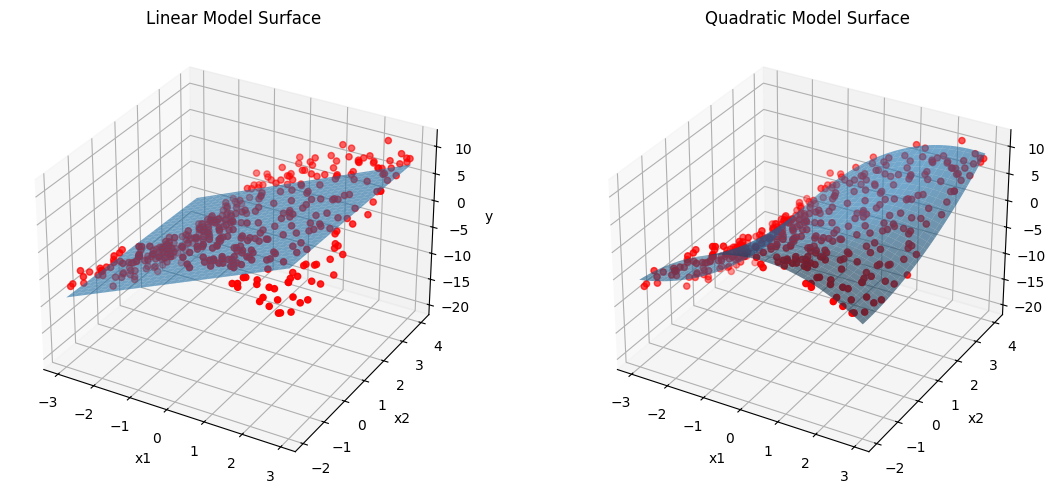

Singular values of A^T A (linear): [1756.292719 1239.97578   282.264531]
Condition number of A^T A (linear): 6.222e+00


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import lstsq, svd



def build_A_linear(X):
    N = X.shape[0]
    return np.hstack([np.ones((N,1)), X])

def build_A_quadratic(X):
    x1 = X[:,0:1]
    x2 = X[:,1:2]
    return np.hstack([np.ones((X.shape[0],1)), x1, x2, x1*x2, x1**2, x2**2])

def true_function(x1, x2):
    return 1.5 + 2.0*x1 - 0.8*x2 + 0.7*x1*x2 - 0.9*x1**2 + 0.3*x2**2

def rms(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))


np.random.seed(42)
N = 400
x1 = np.random.uniform(-3, 3, N)
x2 = np.random.uniform(-2, 4, N)
X = np.column_stack([x1, x2])
noise_sigma = 1.0
y = true_function(x1, x2) + np.random.normal(scale=noise_sigma, size=N)

# Solvers
A_lin = build_A_linear(X)
A_quad = build_A_quadratic(X)
w_lin, *_ = lstsq(A_lin, y, rcond=None)
w_quad, *_ = lstsq(A_quad, y, rcond=None)

y_pred_lin = A_lin.dot(w_lin)
y_pred_quad = A_quad.dot(w_quad)

print("Linear weights (w0, w1, w2):", np.round(w_lin,6))
print("Quadratic weights (w0..w5):", np.round(w_quad,6))
print(f"rms Linear: {rms(y, y_pred_lin):.4f}")
print(f"rms Quadratic: {rms(y, y_pred_quad):.4f}")


grid_n = 60
x1g = np.linspace(X[:,0].min(), X[:,0].max(), grid_n)
x2g = np.linspace(X[:,1].min(), X[:,1].max(), grid_n)
X1g, X2g = np.meshgrid(x1g, x2g)
grid_points = np.column_stack([X1g.ravel(), X2g.ravel()])

Z_lin = build_A_linear(grid_points).dot(w_lin).reshape(X1g.shape)
Z_quad = build_A_quadratic(grid_points).dot(w_quad).reshape(X1g.shape)

fig = plt.figure(figsize=(12,5))

ax1 = fig.add_subplot(1,2,1, projection='3d')
ax1.plot_surface(X1g, X2g, Z_lin, alpha=0.6)
ax1.scatter(X[:,0], X[:,1], y, c='r', s=20)
ax1.set_title('Linear Model Surface')
ax1.set_xlabel('x1'); ax1.set_ylabel('x2'); ax1.set_zlabel('y')

ax2 = fig.add_subplot(1,2,2, projection='3d')
ax2.plot_surface(X1g, X2g, Z_quad, alpha=0.6)
ax2.scatter(X[:,0], X[:,1], y, c='r', s=20)
ax2.set_title('Quadratic Model Surface')
ax2.set_xlabel('x1'); ax2.set_ylabel('x2'); ax2.set_zlabel('y')

plt.tight_layout()
plt.show()

# SVD
C = A_lin.T.dot(A_lin)
U, s, Vt = svd(C)
cond_C = s.max() / s.min()

print("Singular values of A^T A (linear):", np.round(s,6))
print(f"Condition number of A^T A (linear): {cond_C:.3e}")